# Phase 2 - Data Preprocessing

Kysil Oleh and Petrishka Valeriia

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

RANDOM_STATE = 1234

## 2.1 Data Preprocessing Implementation

Target is `failure`, with one observation per row. Only section 2.1 is implemented here; feature selection and the reusable sklearn pipeline belong to sections 2.2 and 2.3.

### Load data and basic phase 1 cleaning/integration

The notebook runs independently from either the project root or `src`. Repeat only deterministic cleaning before splitting: normalize formats, remove duplicate copies, reject invalid or contradictory labels, and validate many-to-one joins. No distribution statistics or imputation values are calculated here.

In [2]:
# CSV files are in ../dataset relative to the src folder
src_dir = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
dataset_dir = src_dir.parent / "dataset"
gateways_df = pd.read_csv(dataset_dir / "gateways.csv", sep=";")
readings_df = pd.read_csv(dataset_dir / "readings.csv", sep="\t")
units_df = pd.read_csv(dataset_dir / "units.csv")
for name, frame in {"gateways": gateways_df, "readings": readings_df, "units": units_df}.items():
    print(name, frame.shape)
    display(frame.head())

gateways (16000, 10)


,firmware_version,idDepot,gatewayId,date_install,vendor,Ipv4,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023/02/11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470.0,Fábio Pinto
1,v2.7.0,94,GW-00001,24 Nov 2018,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406.0,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018/08/20,Schleich,23.152.231.98,-68.7,-9.23071,1022.0,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178.0,Carina Hering
4,v2.7.0,54,GW-00004,21 Sep 2016,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062.0,Chad Salazar


readings (15810, 12)


,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
0,U01837,07 Jan 2023,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,U01444,2023/10/21,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,U01073,"07/17/2023, 05:03:00",3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,U01469,2023-09-02,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,U00271,2023/07/11,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1


units (2000, 7)


,idDepot,last_overhaul,classDuty,serial_number,Manufacturer,hoursService,idUnit
0,69,2016/04/20,H,FN-1865-92664,Correia,19153.0,1
1,85,2022/09/30,H,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,N,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,"12/15/2023, 00:00:00",N,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5


In [3]:
column_names = {
    "idUnit": "id_unit",
    "idDepot": "id_depot",
    "gatewayId": "gateway_id",
    "Ipv4": "ipv4",
    "dbmSignal": "dbm_signal",
    "Technician": "technician",
    "motorCurrent": "motor_current",
    "dpFilter": "dp_filter",
    "oilTemperature": "oil_temperature",
    "pressureReservoir": "pressure_reservoir",
    "pressureOil": "pressure_oil",
    "humidityIntake": "humidity_intake",
    "classDuty": "class_duty",
    "Manufacturer": "manufacturer",
    "hoursService": "hours_service",
}

tables = {"gateways": gateways_df, "readings": readings_df, "units": units_df}
date_columns = {"gateways": "date_install", "readings": "ts_cycle", "units": "last_overhaul"}
normalized = {}

for name, table in tables.items():
    
    # remove exact duplicate rows so repeated copies do not bias the analysis.
    frame = table.drop_duplicates().copy()
    # rename columns to snake_case in the cleaned tables
    frame = frame.rename(columns=column_names)
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
        
    for column in [c for c in ["id_unit", "id_depot"] if c in frame]:
        key_text = frame[column].astype("string")
        
        if name == "readings" and column == "id_unit": 
            # remove the U prefix to match the integer IDs in the metadata tables
            key_text = key_text.str.replace(r"^U", "", regex=True)
            
        numeric = pd.to_numeric(key_text, errors="coerce")
        valid = numeric.notna() & np.isfinite(numeric) & numeric.ge(0) & numeric.mod(1).eq(0)
        
        # replace invalid IDs with missing value, zero is a valid depot ID
        frame[column] = numeric.where(valid).astype("Int64")
        
    frame[date_columns[name]] = pd.to_datetime(frame[date_columns[name]], format="mixed", errors="coerce")
    
    if name == "units":
        frame["class_duty"] = frame["class_duty"].str.lower().replace({"h": "heavy", "l": "light", "n": "normal"})
        
    # remove full-row duplicates that become identical after format normalization.
    normalized[name] = frame.drop_duplicates().copy()

gateways_clean = normalized["gateways"]
readings_clean = normalized["readings"]
units_clean = normalized["units"]
display(gateways_clean)
display(readings_clean)
display(units_clean)

,firmware_version,id_depot,gateway_id,date_install,vendor,ipv4,dbm_signal,lon,id_unit,technician
0,v2.7.0,46,GW-00000,2023-02-11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470,Fábio Pinto
1,v2.7.0,94,GW-00001,2018-11-24,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018-08-20,Schleich,23.152.231.98,-68.7,-9.23071,1022,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178,Carina Hering
4,v2.7.0,54,GW-00004,2016-09-21,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062,Chad Salazar
...,...,...,...,...,...,...,...,...,...,...
15995,v3.4.1,99,GW-15995,2024-06-11,Simões Lda.,223.105.80.99,-71.4,-6.50930,<NA>,Meghan Patel
15996,v2.7.0,4,GW-15996,2022-07-16,Webb-Blackwell,188.156.69.66,-61.9,-7.13180,<NA>,Brian Coelho
15997,v2.7.0,30,GW-15997,2024-05-06,Palmer-Wilson,244.143.197.78,-68.6,-7.38450,<NA>,André da Almeida
15998,v3.4.1,68,GW-15998,2020-07-26,Kraus Harloff GmbH,238.5.110.95,-68.8,-7.79738,<NA>,Dr. Adriana Cichorius B.Eng.


,id_unit,ts_cycle,motor_current,dp_filter,oil_temperature,pressure_reservoir,pressure_oil,rms_vibration,flowmeter,humidity_intake,current_aux,failure
0,1837,2023-01-07 00:00:00,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,1444,2023-10-21 00:00:00,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,1073,2023-07-17 05:03:00,3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,1469,2023-09-02 00:00:00,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,271,2023-07-11 00:00:00,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1
...,...,...,...,...,...,...,...,...,...,...,...,...
15571,1715,2023-10-03 00:00:00,8.10634,23.75623,38.55659,8.46866,4.01351,NaN,20.45578,81.22487,3.44488,0
15572,1355,2023-07-19 06:48:00,6.25650,22.18533,43.43464,8.57624,3.80081,2.38926,32.42021,21.72667,2.03999,0
15573,971,2023-11-12 14:06:00,7.93083,28.02206,65.17459,9.23116,3.58476,4.64216,30.77456,55.17802,1.72297,0
15574,159,2023-11-29 00:00:00,5.95949,39.84336,65.75819,8.57829,3.73022,2.46270,27.35111,58.52541,2.79068,0


,id_depot,last_overhaul,class_duty,serial_number,manufacturer,hours_service,id_unit
0,69,2016-04-20,heavy,FN-1865-92664,Correia,19153.0,1
1,85,2022-09-30,heavy,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,normal,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,2023-12-15,normal,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5
...,...,...,...,...,...,...,...
1995,73,2024-07-28,light,GI-2985-30885,Klein-Chavez,3345.0,1996
1996,76,2023-07-01,light,OG-0205-65156,Mayo LLC,5703.6,1997
1997,58,2021-03-21,normal,FA-1584-67680,Webb-Blackwell,11374.7,1998
1998,105,2021-09-15,1,JS-9450-43578,Pacheco,7251.0,1999


Cleaning loop copied from phase 1

In [4]:
sensor_columns = ["motor_current", "dp_filter", "oil_temperature", "pressure_reservoir", "pressure_oil", "rms_vibration", "flowmeter", "humidity_intake", "current_aux"]

for column in sensor_columns:
    values = readings_clean[column]
    invalid = values.notna() & ~np.isfinite(values)
    
    if column == "oil_temperature":
        invalid |= values.eq(-999)
        
    if column == "humidity_intake":
        invalid |= values.notna() & ~values.between(0, 100)
        
    readings_clean.loc[invalid, column] = np.nan

invalid_hours = units_clean["hours_service"].lt(0) | (units_clean["hours_service"].notna() & ~np.isfinite(units_clean["hours_service"]))

# remove negative or infinite service hours by replacing them with missing values
units_clean.loc[invalid_hours, "hours_service"] = np.nan
invalid_longitude = gateways_clean["lon"].notna() & ~gateways_clean["lon"].between(-180, 180)

# remove coordinates outside the valid longitude range
gateways_clean.loc[invalid_longitude, "lon"] = np.nan

In [5]:
cycle_keys = ["id_unit", "ts_cycle"]
conflicting_labels = readings_clean.groupby(cycle_keys, dropna=False)["failure"].transform("nunique").gt(1)
valid_readings = readings_clean["id_unit"].notna() & readings_clean["ts_cycle"].notna()
valid_readings &= readings_clean["failure"].isin([0, 1]) & ~conflicting_labels

# remove readings with invalid IDs/dates/labels or unresolved contradictory cycle labels
readings_for_merge = readings_clean.loc[valid_readings].copy()

# exclude unassigned gateways from the unit join
linked_gateways = gateways_clean.loc[gateways_clean["id_unit"].notna()].copy()
gateway_metadata = linked_gateways.rename(columns={c: f"gateway_{c}" for c in linked_gateways if c != "id_unit"})
integrated_df = readings_for_merge.merge(units_clean, on="id_unit", how="left", validate="many_to_one", indicator="unit_match")

# remove readings whose IDs have no matching unit metadata
cleaned_df = integrated_df.loc[integrated_df["unit_match"].eq("both")].copy()

# remove the temporary merge indicator once unmatched readings have been excluded
cleaned_df = cleaned_df.drop(columns="unit_match")
cleaned_df = cleaned_df.merge(gateway_metadata, on="id_unit", how="left", validate="many_to_one")
cleaned_df = cleaned_df.reset_index(drop=True)

print(f"Integrated data: {cleaned_df.shape[0]:,} readings, {cleaned_df.shape[1]} columns")
display(cleaned_df.head(n=5))

Integrated data: 15,397 readings, 27 columns


,id_unit,ts_cycle,motor_current,dp_filter,oil_temperature,pressure_reservoir,pressure_oil,rms_vibration,flowmeter,humidity_intake,...,hours_service,gateway_firmware_version,gateway_id_depot,gateway_gateway_id,gateway_date_install,gateway_vendor,gateway_ipv4,gateway_dbm_signal,gateway_lon,gateway_technician
0,1837,2023-01-07 00:00:00,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,...,15380.2,v2.7.0,48,GW-01390,2020-03-02,Figueiredo e Filhos,164.97.196.111,-76.8,-8.39000,Ahmed Bachmann
1,1444,2023-10-21 00:00:00,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,...,17358.0,v3.4.1,89,GW-00829,2020-04-23,Murray PLC,211.187.30.38,-80.2,-8.31471,Gustavo Andrade
2,1073,2023-07-17 05:03:00,3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,...,19389.9,v2.7.0,26,GW-01692,2018-01-14,Miller-Parker,14.144.63.149,-55.7,-8.43676,Henry Salinas
3,1469,2023-09-02 00:00:00,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,...,3564.2,v3.4.1,39,GW-01796,2019-01-01,"Camacho, Lowe and Robinson",244.177.113.187,-56.5,-7.76988,Inês Matos
4,271,2023-07-11 00:00:00,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,...,45000.0,v2.7.0,19,GW-01375,2017-12-06,Marques,21.85.158.5,-75.7,-6.85225,Ricardo Carvalho


### 2.1.A: Split into training and test sets

Use a fixed 80% / 20% split of units. The split does not use failure labels to choose units

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(cleaned_df, groups=cleaned_df["id_unit"]))
train_df = cleaned_df.iloc[train_index].copy()
test_df = cleaned_df.iloc[test_index].copy()

display(pd.DataFrame({
    "readings": [len(train_df), len(test_df)],
    "units": [train_df["id_unit"].nunique(), test_df["id_unit"].nunique()],
    "reading_share": [len(train_df) / len(cleaned_df), len(test_df) / len(cleaned_df)]
}, index=["train", "test"]))
print(f"Training failure rate: {train_df['failure'].mean():.2%}")
print(f"Control failure rate: {test_df['failure'].mean():.2%}")

,readings,units,reading_share
train,12306,1599,0.799247
test,3091,400,0.200753


Training failure rate: 12.26%
Control failure rate: 11.55%


### 2.1.B: One row per observation and numerical attributes

Keep all nine sensors, service hours and gateway signal strength. Convert the overhaul date to `days_since_overhaul`, measured from the reading date. Negative intervals become missing values. Keep both pressure measurements for now

Encode duty class, manufacturer, firmware, gateway vendor and unit depot as nominal categories. Reuse the Phase 1 duty normalization, the same categories are used here. Depot numbers are labels, not a continuous measurement, so one-hot encoding is used

Exclude unit/device identifiers, serial numbers, IP addresses and technician names because they identify equipment or people. Unit IDs and cycle dates remain in `train_df` for debug.

In [7]:
train_df["days_since_overhaul"] = (train_df["ts_cycle"] - train_df["last_overhaul"]).dt.total_seconds() / 86400
negative_intervals = train_df["days_since_overhaul"].lt(0)
train_df.loc[negative_intervals, "days_since_overhaul"] = np.nan
print(f"Negative overhaul intervals masked: {negative_intervals.sum()}")

numeric_columns = sensor_columns + ["hours_service", "gateway_dbm_signal", "days_since_overhaul"]
# Gateway columns acquired a prefix during the Phase 1 join.
categorical_columns = ["class_duty", "manufacturer", "gateway_firmware_version", "gateway_vendor", "id_depot"]
X_train_numeric = train_df[numeric_columns].astype(float)
X_train_categorical = train_df[categorical_columns].astype("string").fillna("missing").astype(str)
y_train = train_df["failure"].astype(int).rename("failure")

missing_summary = pd.DataFrame({"missing": X_train_numeric.isna().sum(),
                               "missing_share": X_train_numeric.isna().mean()})
display(missing_summary)

numeric_imputer = SimpleImputer(strategy="median")
numeric_imputed = pd.DataFrame(numeric_imputer.fit_transform(X_train_numeric),
                               columns=numeric_columns, index=train_df.index)
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float64)
categorical_encoded = pd.DataFrame(encoder.fit_transform(X_train_categorical),
                                  columns=encoder.get_feature_names_out(categorical_columns),
                                  index=train_df.index)
display(pd.Series(numeric_imputer.statistics_, index=numeric_columns, name="training_median"))
print(f"Categorical attributes expanded to {categorical_encoded.shape[1]} numerical columns")
display(categorical_encoded.head(n=5))

Negative overhaul intervals masked: 1859


,missing,missing_share
motor_current,0,0.000000
dp_filter,494,0.040143
oil_temperature,37,0.003007
pressure_reservoir,0,0.000000
pressure_oil,0,0.000000
rms_vibration,467,0.037949
flowmeter,0,0.000000
humidity_intake,631,0.051276
current_aux,0,0.000000
hours_service,648,0.052657


motor_current              5.125140
dp_filter                 21.390310
oil_temperature           55.157250
pressure_reservoir         8.701845
pressure_oil               3.696375
rms_vibration              2.694800
flowmeter                 28.036380
humidity_intake           53.193540
current_aux                2.485335
hours_service          12486.400000
gateway_dbm_signal       -70.000000
days_since_overhaul     1546.000000
Name: training_median, dtype: float64

Categorical attributes expanded to 208 numerical columns


,class_duty_1,class_duty_2,class_duty_3,class_duty_heavy,class_duty_light,class_duty_med,class_duty_normal,"manufacturer_Abbott, Duncan and Barnes","manufacturer_Camacho, Lowe and Robinson",manufacturer_Campos,...,id_depot_90,id_depot_91,id_depot_92,id_depot_93,id_depot_94,id_depot_95,id_depot_96,id_depot_97,id_depot_98,id_depot_99
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 2.1.C: Comparing two scaling techniques

Fit StandardScaler (zero mean and unit population standard deviation) and MinMaxScaler (training range 0 to 1) to the same training data. One-hot columns remain 0/1. Scaling changes units but does not remove skewness. Standard scaling is sensitive to extremes; min-max scaling can compress ordinary values when a rare extreme sets the range

In [8]:
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
scaled_variants = {
    "original": numeric_imputed,
    "standard": pd.DataFrame(standard_scaler.fit_transform(numeric_imputed), columns=numeric_columns, index=train_df.index),
    "minmax": pd.DataFrame(minmax_scaler.fit_transform(numeric_imputed), columns=numeric_columns, index=train_df.index)
}
scaling_summary = pd.concat({name: pd.DataFrame({
    "mean": frame.mean(), "std_ddof0": frame.std(ddof=0),
    "min": frame.min(), "max": frame.max(), "skewness": frame.skew()
}) for name, frame in scaled_variants.items()}, names=["scaling", "feature"])
display(scaling_summary.round(3))

mean  std_ddof0       min        max  \
scaling  feature                                                          
original motor_current            5.349      3.850     0.415     99.000   
         dp_filter               23.913     10.835     7.110    120.000   
         oil_temperature         54.988     11.973    15.000     95.000   
         pressure_reservoir       8.694      0.600     6.500     10.500   
         pressure_oil             3.697      0.562     1.546      5.588   
         rms_vibration            3.045      1.611     0.500     14.000   
         flowmeter               27.984      4.024    15.000     40.000   
         humidity_intake         52.785     24.018    10.024     94.993   
         current_aux              2.496      0.832     0.000      5.528   
         hours_service        14414.768   8492.153  2069.100  45000.000   
         gateway_dbm_signal     -70.042      9.796  -100.200    -40.000   
         days_since_overhaul   1548.575    833.917     0.000   3278.000   
standard motor_current           -0.000      1.000    -1.281     24.323   
         dp_filter                0.000      1.000    -1.551      8.869   
         oil_temperature          0.000      1.000    -3.340      3.342   
         pressure_reservoir       0.000      1.000    -3.657      3.011   
         pressure_oil            -0.000      1.000    -3.825      3.363   
         rms_vibration            0.000      1.000    -1.580      6.801   
         flowmeter                0.000      1.000    -3.227      2.986   
         humidity_intake          0.000      1.000    -1.780      1.757   
         current_aux             -0.000      1.000    -3.001      3.646   
         hours_service           -0.000      1.000    -1.454      3.602   
         gateway_dbm_signal      -0.000      1.000    -3.079      3.067   
         days_since_overhaul      0.000      1.000    -1.857      2.074   
minmax   motor_current            0.050      0.039     0.000      1.000   
         dp_filter                0.149      0.096     0.000      1.000   
         oil_temperature          0.500      0.150     0.000      1.000   
         pressure_reservoir       0.548      0.150     0.000      1.000   
         pressure_oil             0.532      0.139     0.000      1.000   
         rms_vibration            0.189      0.119     0.000      1.000   
         flowmeter                0.519      0.161     0.000      1.000   
         humidity_intake          0.503      0.283     0.000      1.000   
         current_aux              0.451      0.150     0.000      1.000   
         hours_service            0.288      0.198     0.000      1.000   
         gateway_dbm_signal       0.501      0.163     0.000      1.000   
         days_since_overhaul      0.472      0.254     0.000      1.000   

                              skewness  
scaling  feature                        
original motor_current          18.709  
         dp_filter               1.957  
         oil_temperature        -0.033  
         pressure_reservoir     -0.039  
         pressure_oil           -0.037  
         rms_vibration           1.775  
         flowmeter              -0.018  
         humidity_intake        -0.018  
         current_aux             0.023  
         hours_service           1.514  
         gateway_dbm_signal      0.003  
         days_since_overhaul     0.020  
standard motor_current          18.709  
         dp_filter               1.957  
         oil_temperature        -0.033  
         pressure_reservoir     -0.039  
         pressure_oil           -0.037  
         rms_vibration           1.775  
         flowmeter              -0.018  
         humidity_intake        -0.018  
         current_aux             0.023  
         hours_service           1.514  
         gateway_dbm_signal      0.003  
         days_since_overhaul     0.020  
minmax   motor_current          18.709  
         dp_filter               1.957  
         oil_temperature        -0.0

### Compare two distribution transformations

Phase 1 identified right-skewed `dp_filter`, `rms_vibration` and `hours_service`, and extreme `motor_current` measurements. Use Yeo-Johnson PowerTransformer and QuantileTransformer with normal output on these four features. Both are fitted only on imputed training values.

Yeo-Johnson learns a smooth power transformation and supports zero/negative values. Quantile transformation maps empirical ranks to a normal distribution. It can strongly reduce skewness but changes distances

,original,yeo_johnson,quantile_normal
motor_current,18.709,-0.054,0.109
dp_filter,1.957,0.007,0.008
rms_vibration,1.775,0.005,0.014
hours_service,1.514,-0.000,1.010


motor_current   -0.147386
dp_filter       -0.377301
rms_vibration   -0.379200
hours_service    0.030507
Name: Yeo-Johnson, dtype: float64

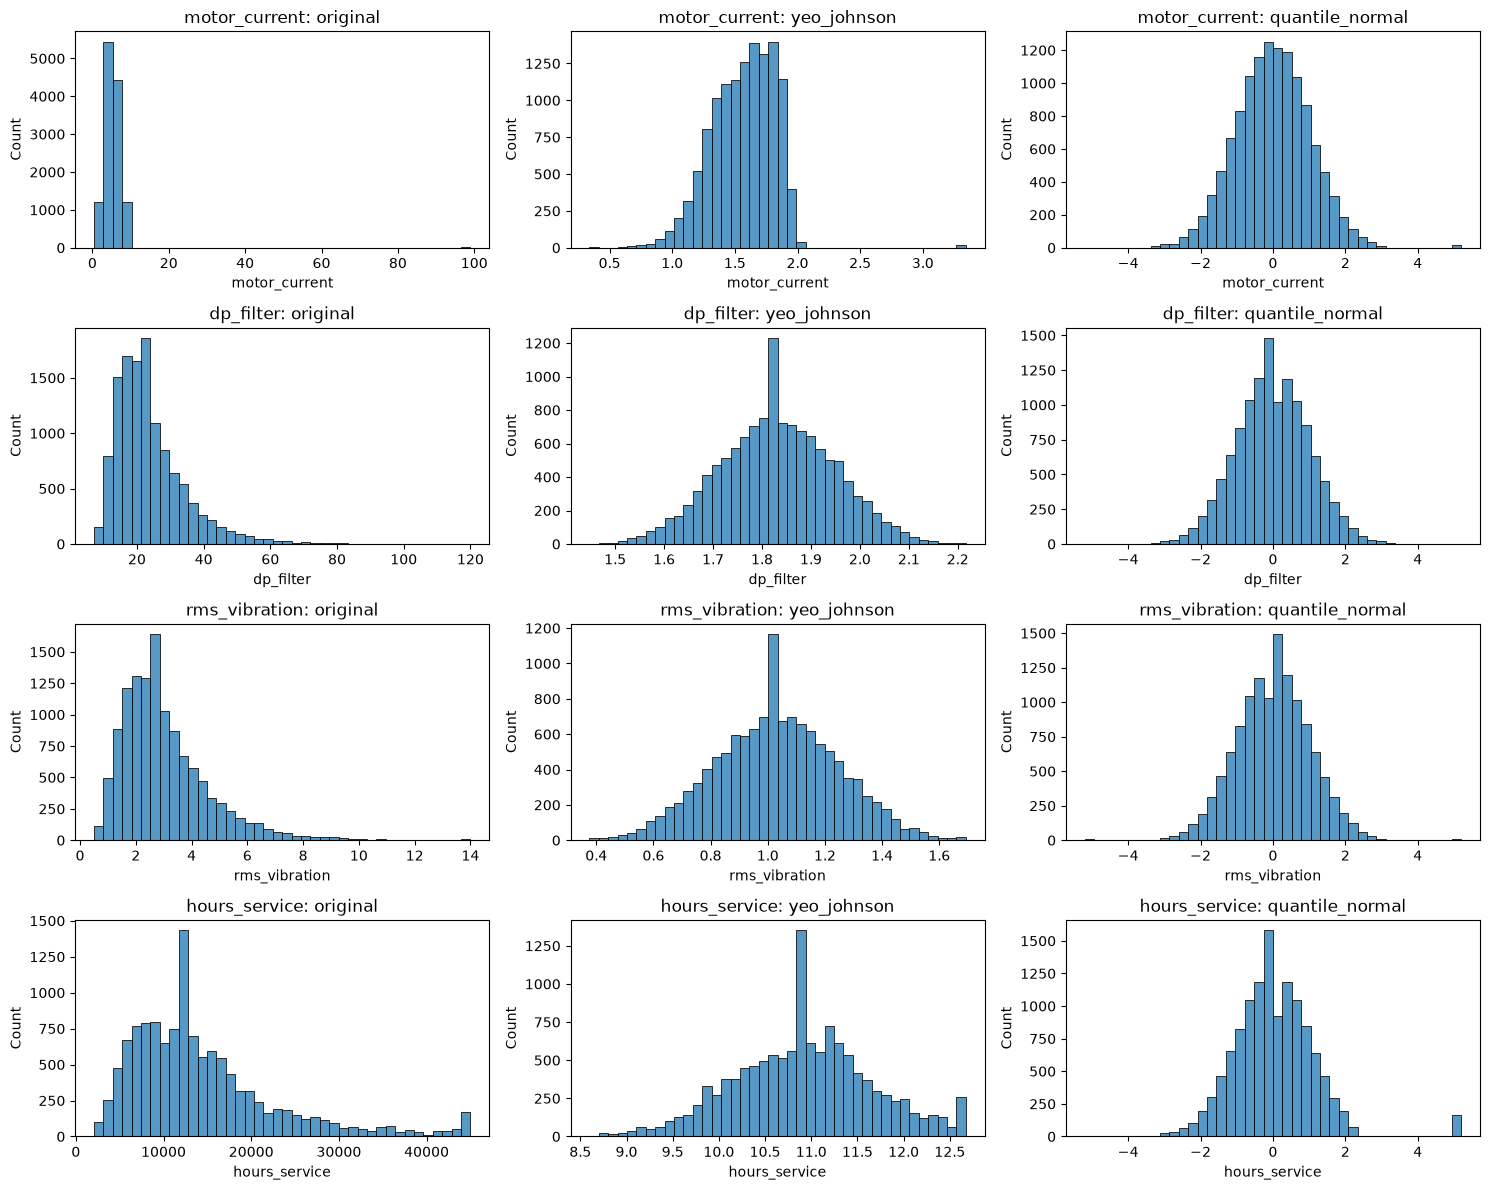

In [9]:
transform_columns = ["motor_current", "dp_filter", "rms_vibration", "hours_service"]
power_transformer = PowerTransformer(method="yeo-johnson", standardize=False)
quantile_transformer = QuantileTransformer(n_quantiles=min(1000, len(numeric_imputed)),
                                           output_distribution="normal", random_state=RANDOM_STATE)
distribution_variants = {
    "original": numeric_imputed[transform_columns],
    "yeo_johnson": pd.DataFrame(power_transformer.fit_transform(numeric_imputed[transform_columns]),
                                columns=transform_columns, index=train_df.index),
    "quantile_normal": pd.DataFrame(quantile_transformer.fit_transform(numeric_imputed[transform_columns]),
                                    columns=transform_columns, index=train_df.index)
}
display(pd.DataFrame({name: frame.skew() for name, frame in distribution_variants.items()}).round(3))
display(pd.Series(power_transformer.lambdas_, index=transform_columns, name="Yeo-Johnson"))

fig, axes = plt.subplots(len(transform_columns), 3, figsize=(15, 12))
for row, column in enumerate(transform_columns):
    for col, (name, frame) in enumerate(distribution_variants.items()):
        sns.histplot(frame[column], bins=40, ax=axes[row, col])
        axes[row, col].set_title(f"{column}: {name}")
plt.tight_layout()
plt.show()

### 2.1.D: Docs

Yeo-Johnson reduces skewness from 17.965 to -0.071 for motor current, from 1.965 to 0.006 for filter pressure, from 1.775 to 0.004 for vibration, and from 1.518 to approximately zero for service hours.

Quantile-normal transformation also reduces skewness, but service hours retain skewness of 1.021. Repeated values and clipped limits cannot be separated by a rank mapping. The scaling comparison shows that scaling alone preserves skewness: the extreme motor current still reaches 22.308 standard deviations, while min-max scaling leaves a standard deviation of only 0.043. Because of that we need to apply the power transformation before scaling.

Use median imputation, Yeo-Johnson on the four skewed/extreme attributes, then standard scaling of all continuous attributes and one-hot encoding of the categories. The histogram and skewness comparison documents how the two distribution transformations change the data. Yeo-Johnson is the current choice because it reduces long tails through a smooth transformation while retaining more magnitude information than empirical rank mapping.

We could reconsider these choices in later sections.

In [10]:
numeric_transformed = numeric_imputed.copy()
numeric_transformed[transform_columns] = distribution_variants["yeo_johnson"]
final_scaler = StandardScaler()
numeric_scaled = pd.DataFrame(final_scaler.fit_transform(numeric_transformed),
                              columns=numeric_columns, index=train_df.index)
X_train_preprocessed = pd.concat([numeric_scaled, categorical_encoded], axis=1)
train_preprocessed = pd.concat([X_train_preprocessed, y_train], axis=1)

assert len(train_preprocessed) == len(train_df)
assert X_train_preprocessed.index.equals(y_train.index)
assert "failure" not in X_train_preprocessed.columns
assert train_preprocessed.columns.is_unique
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in train_preprocessed.dtypes)
assert np.isfinite(train_preprocessed.to_numpy()).all()
assert y_train.isin([0, 1]).all()
assert np.allclose(numeric_scaled.mean(), 0, atol=1e-8)
assert np.allclose(numeric_scaled.std(ddof=0), 1, atol=1e-8)

display(train_preprocessed.head())
print(f"Training result: {len(train_preprocessed):,} observations, {X_train_preprocessed.shape[1]} numerical predictors and one target")

# Generated output is kept in the project's existing ignored tmp directory.
output_dir = dataset_dir.parent / "tmp" / "phase2"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "train_preprocessed.csv"
train_preprocessed.to_csv(output_path, index=False)
print(f"Saved: {output_path.relative_to(dataset_dir.parent).as_posix()}")

,motor_current,dp_filter,oil_temperature,pressure_reservoir,pressure_oil,rms_vibration,flowmeter,humidity_intake,current_aux,hours_service,...,id_depot_91,id_depot_92,id_depot_93,id_depot_94,id_depot_95,id_depot_96,id_depot_97,id_depot_98,id_depot_99,failure
1,-0.956990,0.903392,0.200712,1.208785,2.118133,1.832536,0.400124,-1.709563,0.618187,0.603401,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,-0.600643,0.492022,0.513847,-1.451242,-1.130626,0.159878,-0.760312,0.397550,-1.988861,0.803493,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,-0.750758,0.153521,0.539808,-0.045996,0.502325,0.319916,0.440195,-1.270986,1.945633,-2.185185,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
5,0.917402,-1.126337,-0.148477,1.082008,1.445308,0.207433,0.183370,1.275669,1.173904,0.462883,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0
7,-1.059805,-0.883702,-0.688401,-0.441880,0.366917,-0.449247,0.428338,-0.284115,0.669001,-1.329451,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


Training result: 12,306 observations, 220 numerical predictors and one target
Saved: tmp/phase2/train_preprocessed.csv


The CSV contains one retained reading per row, numerical predictors and the unchanged binary target. `train_df` preserves the original row indices, unit IDs and timestamps for later grouped validation; they are excluded from the predictor matrix. `test_df` remains untransformed. The fitted imputer, encoder, transformers and scalers remain available in this notebook session. Packaging these steps into a reusable sklearn pipeline is left for section 2.3.

## 2.2 Feature Selection for Machine Learning

The goal of this section is to identify which predictor attributes contain useful information for predicting the binary target `failure`. All selection methods are fitted using the training data only `X_train_preprocessed`. `K` is the number of attributes each technique may choose later (its top 10). `attribute_of` maps each of the 220 columns to the attribute it came from, a one-hot column maps to its prefix, so `class_duty_1` becomes `class_duty`. 

In [25]:
from functools import partial
from sklearn.feature_selection import VarianceThreshold, SelectKBest, SelectFromModel, f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

X_train = X_train_preprocessed
y_train = y_train.loc[X_train.index]
K = 10

sources = numeric_columns + categorical_columns
attribute_of = {c: next(a for a in sources if c == a or c.startswith(a + "_")) for c in X_train.columns}

def by_attribute(column_scores, columns):
    return pd.Series(column_scores, index=columns).groupby(attribute_of).max()

### Variance threshold

Variance threshold removes one-hot columns whose variance is 0.01 or less, which means the level occurs in about 1% of the readings or fewer. For a binary one-hot column, variance depends on how often that category occurs, so this threshold removes very rare category indicators that contain little variation in this training sample.

In [40]:
variance_selector = VarianceThreshold(threshold=0.01)
X_train_variance = pd.DataFrame(variance_selector.fit_transform(X_train), columns=X_train.columns[variance_selector.get_support()], index=X_train.index)
display(X_train_variance.columns.map(attribute_of).value_counts().rename("Columns after treshold"))

manufacturer                39
gateway_vendor              39
id_depot                    26
class_duty                   7
gateway_firmware_version     3
motor_current                1
dp_filter                    1
oil_temperature              1
pressure_reservoir           1
pressure_oil                 1
rms_vibration                1
flowmeter                    1
humidity_intake              1
current_aux                  1
hours_service                1
gateway_dbm_signal           1
days_since_overhaul          1
Name: Columns after treshold, dtype: int64

### Mutual information

Measures how much a column reduces uncertainty about failure, and it detects non-linear dependence as well as linear. One-hot columns are treated as discrete and sensor columns as continuous. k="all" keeps every column’s score instead of choosing the best k. The `partial(...)` configuration identifies which columns are discrete and sets a reproducible random seed. It calculates scores for all columns, aggregates them to original attributes, and displays the ten highest-scoring attributes.

In [41]:
mutual_info_selector = SelectKBest(partial(mutual_info_classif, discrete_features=~X_train_variance.columns.isin(numeric_columns), random_state=RANDOM_STATE), k="all").fit(X_train_variance, y_train)
mutual_info = by_attribute(mutual_info_selector.scores_, X_train_variance.columns)
display(mutual_info.nlargest(K))

dp_filter                   0.033907
rms_vibration               0.027342
hours_service               0.016182
motor_current               0.008434
gateway_firmware_version    0.008248
class_duty                  0.006041
gateway_dbm_signal          0.005844
current_aux                 0.005183
days_since_overhaul         0.004099
flowmeter                   0.002733
dtype: float64

### ANOVA F-test

Compares the mean of a column between failures and non-failures against the spread within each group, so it only detects linear differences. A larger F-statistic generally indicates stronger evidence that the class means differ.

In [42]:
anova_selector = SelectKBest(f_classif, k="all").fit(X_train_variance, y_train)
anova_f = by_attribute(anova_selector.scores_, X_train_variance.columns)
display(anova_f.nlargest(K)) 

gateway_firmware_version    210.710518
hours_service               185.067534
class_duty                  160.596980
dp_filter                   157.139291
pressure_reservoir           99.377451
current_aux                  81.925843
pressure_oil                 66.713906
flowmeter                    34.627558
motor_current                31.885589
rms_vibration                30.174125
dtype: float64

### SelectionFromModel

A Random Forest classifier estimates feature importance from the reduction in impurity across its trees. This can capture nonlinear relationships and interactions that a univariate test may miss. `SelectFromModel` is fitted on the training data, and the fitted forest's importance scores are used to rank the original attributes.

In [43]:
forest_selector = SelectFromModel(RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)).fit(X_train_variance, y_train)
forest = by_attribute(forest_selector.estimator_.feature_importances_, X_train_variance.columns)
display(forest.nlargest(K)) 

dp_filter             0.116618
hours_service         0.083891
motor_current         0.077745
rms_vibration         0.077547
pressure_reservoir    0.067135
current_aux           0.064696
pressure_oil          0.054923
flowmeter             0.054676
oil_temperature       0.051692
gateway_dbm_signal    0.046774
dtype: float64

### Comparison of the techniques

Every method gives column scores, and each attribute gets the maximum over its columns. Scores differ in scale between methods, so each method turns its scores into ranks from 1 to 17. `chosen` marks an attribute when its rank is 10 or better, so it is that method’s top 10. This makes agreement and disagreement between the three approaches easy to inspect.

In [46]:
scores = pd.DataFrame({"mutual_info": mutual_info, "anova_f": anova_f, "forest": forest})
ranks = scores.rank(ascending=False)
chosen = ranks <= K

comparison = chosen.assign(techniques=chosen.sum(axis=1)).sort_values("techniques", ascending=False)
display(comparison)

,mutual_info,anova_f,forest,techniques
current_aux,True,True,True,3
rms_vibration,True,True,True,3
dp_filter,True,True,True,3
flowmeter,True,True,True,3
hours_service,True,True,True,3
motor_current,True,True,True,3
class_duty,True,True,False,2
gateway_firmware_version,True,True,False,2
gateway_dbm_signal,True,False,True,2
pressure_oil,False,True,True,2


### Ranking

The final order is the mean of the three ranks. `rank_std` is the standard deviation of the three ranks and shows how much the methods disagree. It also breaks ties in the mean rank. An attribute is selected if at least 2 of the 3 methods chose it. We build the ranking table, including each method's rank, the mean rank, rank variability, and the number of methods selecting each attribute. It sorts by mean rank and then by rank standard deviation, and stores the attributes selected by at least two methods in `selected_attributes`.

In [37]:
ranking = ranks.add_prefix("rank_")
ranking["mean_rank"] = ranks.mean(axis=1)
ranking["rank_std"] = ranks.std(axis=1)
ranking["techniques"] = chosen.sum(axis=1)
ranking = ranking.sort_values(["mean_rank", "rank_std"])
ranking.insert(0, "position", range(1, len(ranking) + 1))
display(ranking.round(2))

selected_attributes = ranking.index[ranking["techniques"] >= 2].tolist()

,position,rank_mutual_info,rank_anova_f,rank_forest,mean_rank,rank_std,techniques
dp_filter,1,1.0,4.0,1.0,2.00,1.73,3
hours_service,2,3.0,2.0,2.0,2.33,0.58,3
motor_current,3,4.0,9.0,3.0,5.33,3.21,3
rms_vibration,4,2.0,10.0,4.0,5.33,4.16,3
gateway_firmware_version,5,5.0,1.0,13.0,6.33,6.11,2
current_aux,6,8.0,6.0,6.0,6.67,1.15,3
pressure_reservoir,7,13.0,5.0,5.0,7.67,4.62,2
class_duty,8,6.0,3.0,14.0,7.67,5.69,2
flowmeter,9,10.0,8.0,8.0,8.67,1.15,3
gateway_dbm_signal,10,7.0,14.0,10.0,10.33,3.51,2


### Documentation
...

## 2.3 Reproducibility of Preprocessing

### Reusable preprocessing

`add_days_since_overhaul` derives the number of days between each reading timestamp and the last overhaul date, and turns negative intervals into missing values because they are not valid elapsed times. `to_text` converts categorical values to strings and represents missing categories with the explicit label `missing`. The target is kept separately in `y_train` and `y_test`, it is not included in the predictor columns.

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_selection import VarianceThreshold

def add_days_since_overhaul(df):
    df = df.copy()
    days = (df["ts_cycle"] - df["last_overhaul"]).dt.total_seconds() / 86400
    df["days_since_overhaul"] = days.where(days >= 0)
    return df

def to_text(df):
    return df.astype("string").fillna("missing").astype(str)

selected_numeric = [c for c in numeric_columns if c in selected_attributes]
selected_categorical = [c for c in categorical_columns if c in selected_attributes]
skewed = [c for c in transform_columns if c in selected_numeric]

feature_columns = ["ts_cycle", "last_overhaul"] + [c for c in numeric_columns if c != "days_since_overhaul"] + categorical_columns
X_train_raw, y_train = train_df[feature_columns], train_df["failure"].astype(int)
X_test_raw, y_test = test_df[feature_columns], test_df["failure"].astype(int)

### sklearn pipeline

The numeric pipeline fills missing values with the training-set median, applies a Yeo–Johnson power transformation to the selected skewed features, and standardizes numeric columns to zero mean and unit variance. The categorical pipeline converts values to text, fills missing values as missing, and one-hot encodes categories.

In [48]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("power", ColumnTransformer([("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False), skewed)], remainder="passthrough", verbose_feature_names_out=False)),
    ("scaler", StandardScaler())])

categorical_pipeline = Pipeline(steps=[
    ("text", FunctionTransformer(to_text, feature_names_out="one-to-one")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor_pipeline = Pipeline(steps=[
    ("overhaul", FunctionTransformer(add_days_since_overhaul, feature_names_out=lambda t, names: [*names, "days_since_overhaul"])),
    ("columns", ColumnTransformer([("numeric", numeric_pipeline, selected_numeric), ("categorical", categorical_pipeline, selected_categorical)], verbose_feature_names_out=False)),
    ("variance", VarianceThreshold(threshold=0.01))],
    verbose=True).set_output(transform="pandas")

preprocessor_pipeline.fit(X_train_raw, y_train)

[Pipeline] .......... (step 1 of 3) Processing overhaul, total=   0.4s
[Pipeline] ........... (step 2 of 3) Processing columns, total=   1.0s
[Pipeline] .......... (step 3 of 3) Processing variance, total=   0.0s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('overhaul', ...), ('columns', ...), ...]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['ts_cycle','last_overhaul','motor_current',...,'gateway_firmware_version', 'gateway_vendor','id_depot']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...001F287D83D80>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",<function <la...001F287D82980>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` 

In [52]:
preprocessed_train = preprocessor_pipeline.transform(X_train_raw)
preprocessed_test = preprocessor_pipeline.transform(X_test_raw)
display(preprocessed_train.head())
display(preprocessed_test.head())

assert len(preprocessed_train) == len(X_train_raw)
assert len(preprocessed_test) == len(X_test_raw)

assert preprocessed_train.columns.equals(preprocessed_test.columns)

assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in preprocessed_train.dtypes
)

assert np.isfinite(preprocessed_train.to_numpy()).all()
assert np.isfinite(preprocessed_test.to_numpy()).all()

assert "failure" not in preprocessed_train.columns
assert "failure" not in preprocessed_test.columns

print(preprocessed_train.shape, preprocessed_test.shape)

,motor_current,dp_filter,rms_vibration,hours_service,pressure_reservoir,pressure_oil,flowmeter,current_aux,gateway_dbm_signal,class_duty_1,class_duty_2,class_duty_3,class_duty_heavy,class_duty_light,class_duty_med,class_duty_normal,gateway_firmware_version_v1.2.5,gateway_firmware_version_v2.7.0,gateway_firmware_version_v3.4.1
1,-0.956990,0.903392,1.832536,0.603401,1.208785,2.118133,0.400124,0.618187,-1.036908,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.600643,0.492022,0.159878,0.803493,-1.451242,-1.130626,-0.760312,-1.988861,1.464090,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,-0.750758,0.153521,0.319916,-2.185185,-0.045996,0.502325,0.440195,1.945633,1.382424,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5,0.917402,-1.126337,0.207433,0.462883,1.082008,1.445308,0.183370,1.173904,0.361609,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
7,-1.059805,-0.883702,-0.449247,-1.329451,-0.441880,0.366917,0.428338,0.669001,1.555963,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


,motor_current,dp_filter,rms_vibration,hours_service,pressure_reservoir,pressure_oil,flowmeter,current_aux,gateway_dbm_signal,class_duty_1,class_duty_2,class_duty_3,class_duty_heavy,class_duty_light,class_duty_med,class_duty_normal,gateway_firmware_version_v1.2.5,gateway_firmware_version_v2.7.0,gateway_firmware_version_v3.4.1
0,0.719725,-0.695328,1.570897,0.385512,0.122839,0.269923,-1.040519,0.779719,-0.689831,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,0.409050,0.934751,-0.000083,2.347620,1.212152,0.875346,0.634746,0.652793,-0.577541,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6,1.048506,1.177227,0.907688,-1.430664,0.058559,0.033626,0.061768,-0.926293,-0.567333,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
13,1.306793,0.100508,-0.952015,-0.278835,-0.879889,-0.866426,-0.124865,-0.283522,0.106405,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
16,1.292828,0.723900,0.052268,-0.651057,0.067194,0.915841,-0.898347,0.679618,-0.832745,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


(12306, 19) (3091, 19)


In [51]:
preprocessed_train["failure"] = y_train
preprocessed_train.to_csv(output_dir / "preprocessed_train.csv", index=False)
preprocessed_test["failure"] = y_test
preprocessed_test.to_csv(output_dir / "preprocessed_test.csv", index=False)